# Ces données ne sont pas concluantes, il s'agit d'un partage informatif et il faudra encore pas mal trafficoter le réseau pour essayer de voir si on peut obtenir un truc correct. => Pooling pour éviter d'avoir autant de pixels 128 x 128 que le réseau peu apprendre par coeur

In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# Our own package: the same data pipeline and training functions for every model
from museum_guide.data import prepare_subset
from museum_guide.training import count_parameters, evaluate, fit

# Fix the random seed so that every run gives the same results
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load, split, standardise and batch the style subset (takes about a minute)
style = prepare_subset("style")
print("device:", device, "| classes:", len(style["classes"]), "| train batches:", len(style["train_loader"]))

device: cpu | classes: 27 | train batches: 82


# Deliverable 1: a feed-forward network for artwork classification

## Design choices

| Element | Choice | Why |
|---|---|---|
| Input | 3 x 128 x 128 image, flattened to 49 152 values | default size of the course script (`--size 128`) |
| Hidden layers | 2 layers, 256 then 128 neurons | a simple network, close to the course examples |
| Activation | ReLU | default for hidden layers (TP05) |
| Initialisation | He | recommended with ReLU (TP05, Part D) |
| Output and loss | one logit per class + `CrossEntropyLoss` | standard multi-class recipe (TP05, TP06) |
| Optimiser | Adam, learning rate 1e-3 | usual default of Adam (TP06) |
| Training | 30 epochs, mini-batches of 64 | long enough to see overfitting appear (TP06) |
| Regularisation | none | added and measured in deliverable 2 |

In [2]:
def make_mlp(n_classes, image_shape=(3, 128, 128), hidden_sizes=(256, 128)):
    """Build a feed-forward network (MLP) for colour images, as in TP05 and TP06.

    Args:
        n_classes: number of classes to predict (27 styles or 11 genres).
        image_shape: shape of one input image, (channels, height, width).
        hidden_sizes: number of neurons of each hidden layer.

    Returns:
        An nn.Sequential that maps a batch (B, 3, 128, 128) to (B, n_classes) logits.
    """
    # Turn each image into a vector: (B, 3, 128, 128) -> (B, 49152)
    layers = [nn.Flatten()]
    n_in = image_shape[0] * image_shape[1] * image_shape[2]
    for n_out in hidden_sizes:
        # One hidden layer followed by a ReLU (TP05, Part C)
        layers += [nn.Linear(n_in, n_out), nn.ReLU()]
        n_in = n_out
    # Output layer: one score (logit) per class, no softmax since CrossEntropyLoss applies it
    layers.append(nn.Linear(n_in, n_classes))
    model = nn.Sequential(*layers)

    # He initialisation, recommended for ReLU networks (TP05 Part D, TP06 exercise 21)
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    return model


torch.manual_seed(0)
model = make_mlp(n_classes=len(style["classes"])).to(device)
print(model)
print("parameters:", count_parameters(model))

# Check the output shape on one mini-batch
xb, yb = next(iter(style["train_loader"]))
print("output:", tuple(model(xb.to(device)).shape))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=49152, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): ReLU()
  (5): Linear(in_features=128, out_features=27, bias=True)
)
parameters: 12619547
output: (64, 27)


In [3]:
# Start training 

N_EPOCHS = 30
LEARNING_RATE = 1e-3

# Start again from a fresh network, so that the run does not depend on the cells above
torch.manual_seed(0)
style_model = make_mlp(n_classes=len(style["classes"])).to(device)

# The loss and the optimiser chosen together (see the design choices table)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(style_model.parameters(), lr=LEARNING_RATE)

# Train for N_EPOCHS and keep the history of the metrics for the plots
style_history = fit(
    style_model, style["train_loader"], style["val_loader"], loss_fn, optimizer, N_EPOCHS, device=device
)

epoch  1 | train loss 4.482 acc 0.110 | val loss 5.457 acc 0.045 | 3.7 s
epoch  2 | train loss 3.017 acc 0.122 | val loss 3.617 acc 0.047 | 3.7 s
epoch  3 | train loss 2.917 acc 0.156 | val loss 3.636 acc 0.057 | 4.2 s
epoch  4 | train loss 2.864 acc 0.175 | val loss 3.747 acc 0.048 | 3.5 s
epoch  5 | train loss 2.773 acc 0.194 | val loss 3.788 acc 0.047 | 3.5 s
epoch  6 | train loss 2.701 acc 0.216 | val loss 3.965 acc 0.063 | 4.6 s
epoch  7 | train loss 2.681 acc 0.218 | val loss 3.896 acc 0.038 | 3.9 s
epoch  8 | train loss 2.677 acc 0.220 | val loss 4.018 acc 0.046 | 3.4 s
epoch  9 | train loss 2.626 acc 0.243 | val loss 4.222 acc 0.053 | 3.4 s
epoch 10 | train loss 2.605 acc 0.245 | val loss 3.970 acc 0.052 | 3.4 s
epoch 11 | train loss 2.542 acc 0.265 | val loss 4.120 acc 0.064 | 3.5 s
epoch 12 | train loss 2.505 acc 0.276 | val loss 4.295 acc 0.057 | 3.4 s
epoch 13 | train loss 2.601 acc 0.252 | val loss 4.485 acc 0.049 | 5.1 s
epoch 14 | train loss 2.476 acc 0.279 | val loss 4.

In [4]:
style_history["val_acc"]

[0.044722719141323794,
 0.046511627906976744,
 0.057245080500894455,
 0.04830053667262969,
 0.04740608228980322,
 0.0626118067978533,
 0.038461538461538464,
 0.04561717352415027,
 0.052772808586762074,
 0.0518783542039356,
 0.06350626118067978,
 0.057245080500894455,
 0.049194991055456175,
 0.04740608228980322,
 0.05635062611806798,
 0.06350626118067978,
 0.05635062611806798,
 0.05635062611806798,
 0.06618962432915922,
 0.061717352415026835,
 0.059033989266547404,
 0.06887298747763863,
 0.05992844364937388,
 0.05992844364937388,
 0.06440071556350627,
 0.06440071556350627,
 0.06797853309481217,
 0.06440071556350627,
 0.06529516994633273,
 0.06529516994633273]

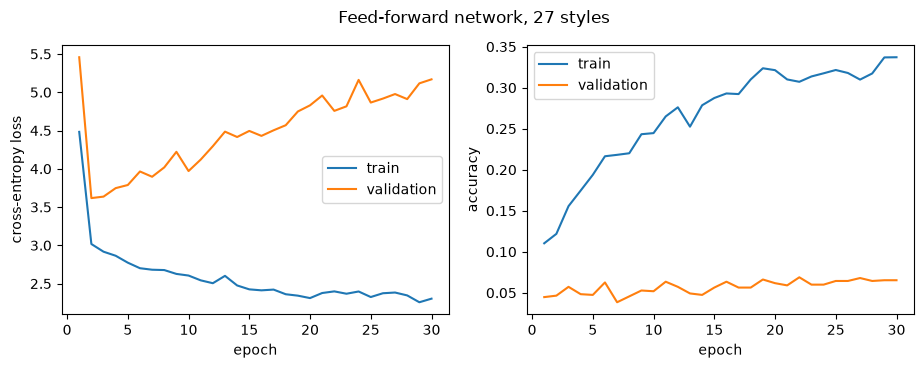

In [5]:
def plot_history(history, title=""):
    """Plot the loss and accuracy curves of a training run, train versus validation, as in TP06.

    Args:
        history: the dictionary returned by fit.
        title: title of the figure.
    """
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

    # Left: the loss (lower is better)
    axes[0].plot(epochs, history["train_loss"], label="train")
    axes[0].plot(epochs, history["val_loss"], label="validation")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("cross-entropy loss")
    axes[0].legend()

    # Right: the accuracy (higher is better)
    axes[1].plot(epochs, history["train_acc"], label="train")
    axes[1].plot(epochs, history["val_acc"], label="validation")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("accuracy")
    axes[1].legend()

    fig.suptitle(title)
    plt.show()


plot_history(style_history, "Feed-forward network, 27 styles")

## Try 2: a simpler network (one hidden layer of 128 neurons)

The first network (256 then 128 neurons, 12.6 M weights) learnt the training images by heart:
the validation loss rose from epoch 2 on, and the validation accuracy stayed close to chance (about 4 %).

| Element | Try 1 | Try 2 |
|---|---|---|
| Hidden layers | 256 then 128 neurons | **1 layer of 128 neurons** |
| Weights | 12.6 M | **6.3 M** |
| Learning rate | 1e-3 | 1e-3 |
| Everything else | ReLU, He, Adam, 30 epochs | unchanged |

parameters: 6295067
epoch  1 | train loss 18.561 acc 0.165 | val loss 24.588 acc 0.068 | 1.8 s
epoch  2 | train loss 14.189 acc 0.187 | val loss 23.168 acc 0.056 | 1.7 s
epoch  3 | train loss 11.673 acc 0.256 | val loss 21.574 acc 0.070 | 1.8 s
epoch  4 | train loss 11.739 acc 0.270 | val loss 23.558 acc 0.047 | 1.8 s
epoch  5 | train loss 10.171 acc 0.307 | val loss 22.992 acc 0.064 | 1.9 s
epoch  6 | train loss 6.928 acc 0.375 | val loss 22.028 acc 0.078 | 1.9 s
epoch  7 | train loss 7.118 acc 0.383 | val loss 22.023 acc 0.074 | 1.9 s
epoch  8 | train loss 6.272 acc 0.386 | val loss 22.820 acc 0.060 | 2.0 s
epoch  9 | train loss 9.526 acc 0.374 | val loss 27.771 acc 0.067 | 2.3 s
epoch 10 | train loss 5.532 acc 0.440 | val loss 23.745 acc 0.063 | 2.2 s
epoch 11 | train loss 5.002 acc 0.469 | val loss 23.215 acc 0.081 | 2.2 s
epoch 12 | train loss 8.265 acc 0.434 | val loss 27.935 acc 0.062 | 2.3 s
epoch 13 | train loss 4.184 acc 0.486 | val loss 23.264 acc 0.057 | 2.2 s
epoch 14 | tr

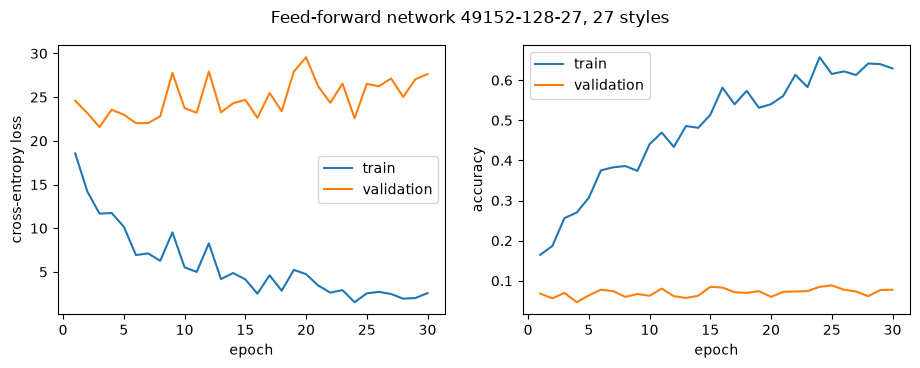

In [6]:
# Second try: a simpler network with one hidden layer of 128 neurons (option A),
# because the 256-128 network learnt the training images by heart
torch.manual_seed(0)
style_model_a = make_mlp(n_classes=len(style["classes"]), hidden_sizes=(128,)).to(device)
print("parameters:", count_parameters(style_model_a))

# Same loss and same optimiser settings as the first try, only the network changes
optimizer = torch.optim.Adam(style_model_a.parameters(), lr=LEARNING_RATE)
style_history_a = fit(
    style_model_a, style["train_loader"], style["val_loader"], loss_fn, optimizer, N_EPOCHS, device=device
)
plot_history(style_history_a, "Feed-forward network 49152-128-27, 27 styles")

## Try 3: a basic network (one hidden layer of 32 neurons)

Try 2 still learnt by heart, and its loss reached 20 to 30 with jumps on the training curve:
the network gives very confident wrong answers. We first test whether a much smaller network is enough.

| Element | Try 2 | Try 3 |
|---|---|---|
| Hidden layers | 1 layer of 128 neurons | **1 layer of 32 neurons** |
| Weights | 6.3 M | **1.6 M** |
| Learning rate | 1e-3 | 1e-3 |
| Everything else | ReLU, He, Adam, 30 epochs | unchanged |

parameters: 1573787
epoch  1 | train loss 8.211 acc 0.123 | val loss 10.083 acc 0.065 | 0.6 s
epoch  2 | train loss 7.412 acc 0.136 | val loss 10.560 acc 0.040 | 0.6 s
epoch  3 | train loss 6.751 acc 0.161 | val loss 10.486 acc 0.055 | 0.6 s
epoch  4 | train loss 6.643 acc 0.183 | val loss 11.371 acc 0.057 | 0.6 s
epoch  5 | train loss 5.657 acc 0.214 | val loss 10.969 acc 0.063 | 0.6 s
epoch  6 | train loss 5.494 acc 0.234 | val loss 11.038 acc 0.058 | 0.6 s
epoch  7 | train loss 5.100 acc 0.245 | val loss 10.855 acc 0.054 | 0.6 s
epoch  8 | train loss 4.075 acc 0.284 | val loss 10.821 acc 0.069 | 0.8 s
epoch  9 | train loss 3.754 acc 0.302 | val loss 10.707 acc 0.055 | 1.9 s
epoch 10 | train loss 4.028 acc 0.306 | val loss 11.251 acc 0.063 | 2.0 s
epoch 11 | train loss 3.692 acc 0.310 | val loss 10.981 acc 0.051 | 2.0 s
epoch 12 | train loss 3.209 acc 0.342 | val loss 10.417 acc 0.059 | 2.0 s
epoch 13 | train loss 3.882 acc 0.330 | val loss 11.838 acc 0.048 | 2.0 s
epoch 14 | train l

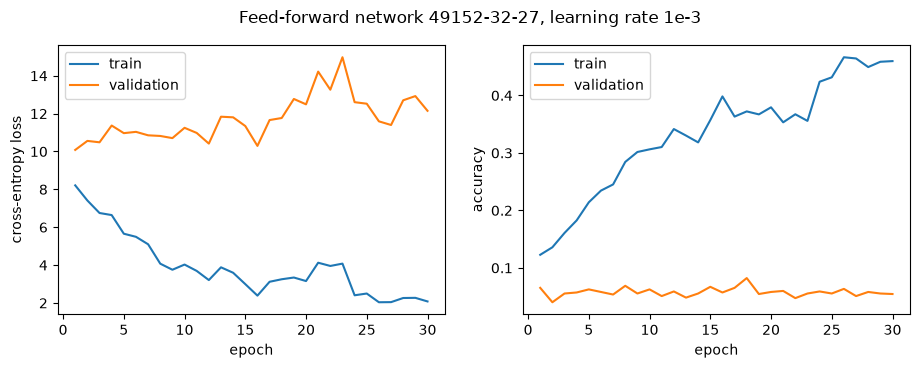

In [7]:
# Third try: a basic network with one hidden layer of 32 neurons.
# Only the size changes: the learning rate stays at 1e-3.
torch.manual_seed(0)
style_model_c = make_mlp(n_classes=len(style["classes"]), hidden_sizes=(32,)).to(device)
print("parameters:", count_parameters(style_model_c))

optimizer = torch.optim.Adam(style_model_c.parameters(), lr=1e-3)
style_history_c = fit(
    style_model_c, style["train_loader"], style["val_loader"], loss_fn, optimizer, N_EPOCHS, device=device
)
plot_history(style_history_c, "Feed-forward network 49152-32-27, learning rate 1e-3")

## Tries 4 to 6: the same three networks with a learning rate 10 times smaller

Tries 1 to 3 changed the size of the network and none of them generalised: the validation accuracy
stayed close to chance (about 4 %), and the losses were very high with jumps on the training curves.
Hypothesis: the steps of the optimiser are too large. Adam moves each weight by about the learning rate
at every step, and each neuron of the first layer has 49 152 inputs: all these small moves add up to
large jumps. We train the same three networks again with a learning rate of 1e-4 instead of 1e-3,
and change nothing else.

In [8]:
def train_style_mlp(hidden_sizes, learning_rate, n_epochs=N_EPOCHS):
    """Build a fresh feed-forward network for the styles and train it with Adam.

    Args:
        hidden_sizes: number of neurons of each hidden layer, for example (128,).
        learning_rate: learning rate of Adam.
        n_epochs: number of epochs.

    Returns:
        (model, history): the trained network and the history returned by fit.
    """
    # Same seed for every try: same initial weights and same order of the mini-batches
    torch.manual_seed(0)
    model = make_mlp(n_classes=len(style["classes"]), hidden_sizes=hidden_sizes).to(device)
    print("parameters:", count_parameters(model))

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = fit(
        model, style["train_loader"], style["val_loader"], loss_fn, optimizer, n_epochs, device=device
    )
    return model, history

### Try 4: two hidden layers (256 then 128 neurons), learning rate 1e-4

| Element | Try 1 | Try 4 |
|---|---|---|
| Hidden layers | 256 then 128 neurons | 256 then 128 neurons |
| Weights | 12.6 M | 12.6 M |
| Learning rate | 1e-3 | **1e-4** |
| Everything else | ReLU, He, Adam, 30 epochs | unchanged |

parameters: 12619547
epoch  1 | train loss 3.053 acc 0.195 | val loss 3.942 acc 0.080 | 3.0 s
epoch  2 | train loss 2.536 acc 0.337 | val loss 3.844 acc 0.097 | 3.3 s
epoch  3 | train loss 2.013 acc 0.453 | val loss 3.936 acc 0.088 | 10.9 s
epoch  4 | train loss 1.738 acc 0.525 | val loss 4.068 acc 0.064 | 7.7 s
epoch  5 | train loss 1.503 acc 0.606 | val loss 4.217 acc 0.080 | 7.0 s
epoch  6 | train loss 1.227 acc 0.681 | val loss 4.360 acc 0.087 | 7.1 s
epoch  7 | train loss 1.236 acc 0.685 | val loss 4.646 acc 0.097 | 4.8 s
epoch  8 | train loss 0.904 acc 0.763 | val loss 4.581 acc 0.101 | 3.2 s
epoch  9 | train loss 0.676 acc 0.831 | val loss 4.666 acc 0.104 | 3.3 s
epoch 10 | train loss 0.700 acc 0.822 | val loss 4.957 acc 0.085 | 3.5 s
epoch 11 | train loss 0.516 acc 0.879 | val loss 4.909 acc 0.102 | 3.3 s
epoch 12 | train loss 0.520 acc 0.875 | val loss 5.057 acc 0.089 | 3.3 s
epoch 13 | train loss 0.517 acc 0.868 | val loss 5.271 acc 0.094 | 3.3 s
epoch 14 | train loss 0.449 a

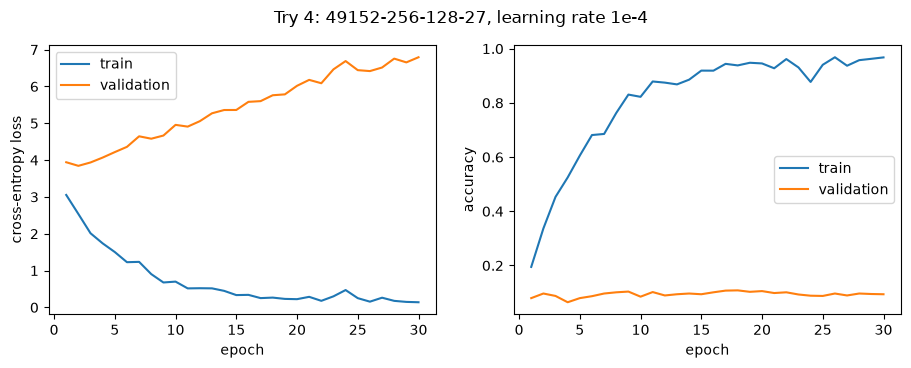

In [9]:
# Try 4: the network of try 1 with a learning rate 10 times smaller
style_model_4, style_history_4 = train_style_mlp(hidden_sizes=(256, 128), learning_rate=1e-4)
plot_history(style_history_4, "Try 4: 49152-256-128-27, learning rate 1e-4")

### Try 6: one hidden layer of 32 neurons, learning rate 1e-4

| Element | Try 3 | Try 6 |
|---|---|---|
| Hidden layers | 1 layer of 32 neurons | 1 layer of 32 neurons |
| Weights | 1.6 M | 1.6 M |
| Learning rate | 1e-3 | **1e-4** |
| Everything else | ReLU, He, Adam, 30 epochs | unchanged |

parameters: 1573787
epoch  1 | train loss 3.277 acc 0.129 | val loss 3.744 acc 0.079 | 0.6 s
epoch  2 | train loss 3.143 acc 0.174 | val loss 3.909 acc 0.067 | 0.6 s
epoch  3 | train loss 2.860 acc 0.211 | val loss 3.911 acc 0.060 | 0.7 s
epoch  4 | train loss 2.652 acc 0.252 | val loss 3.933 acc 0.071 | 0.6 s
epoch  5 | train loss 2.547 acc 0.308 | val loss 4.060 acc 0.077 | 0.6 s
epoch  6 | train loss 2.165 acc 0.396 | val loss 3.891 acc 0.072 | 0.6 s
epoch  7 | train loss 1.997 acc 0.437 | val loss 3.892 acc 0.081 | 0.6 s
epoch  8 | train loss 1.995 acc 0.458 | val loss 4.094 acc 0.058 | 0.6 s
epoch  9 | train loss 1.881 acc 0.489 | val loss 4.188 acc 0.077 | 0.6 s
epoch 10 | train loss 1.674 acc 0.544 | val loss 4.176 acc 0.077 | 0.6 s
epoch 11 | train loss 1.724 acc 0.543 | val loss 4.338 acc 0.070 | 0.6 s
epoch 12 | train loss 1.387 acc 0.639 | val loss 4.188 acc 0.082 | 0.6 s
epoch 13 | train loss 1.524 acc 0.596 | val loss 4.465 acc 0.070 | 0.6 s
epoch 14 | train loss 1.369 acc

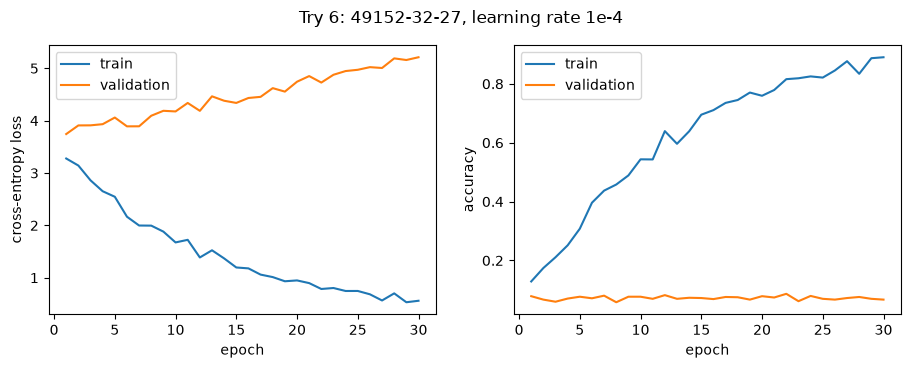

In [10]:
# Try 6: the network of try 3 with a learning rate 10 times smaller
style_model_6, style_history_6 = train_style_mlp(hidden_sizes=(32,), learning_rate=1e-4)
plot_history(style_history_6, "Try 6: 49152-32-27, learning rate 1e-4")
